<a href="https://colab.research.google.com/github/liskangelina/Netflix-Catalog-EDA/blob/main/EDA_Netflix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Katalog Netflix: Strategi Konten dan Arah Pertumbuhan

**Pertanyaan bisnis:** Seperti apa komposisi katalog Netflix, bagaimana strategi konten berubah dari tahun ke tahun, dan perkembangan bisnis kedepannya?

**Data:** 8.807 judul (movie dan TV show) dengan 12 kolom asli.
**Tools:** Python (pandas, numpy, plotly, matplotlib)

## Ringkasan

**FAKTA**
* Katalog berisi 8.807 judul, 69,6% film dan 30,4% serial.
* US terlibat di 3.690 judul (41,9%), India 1.046, dan UK 806.
* Porsi film per negara: India 92,0%, US 74,6%, UK 66,3% (serial UK 33,7%).
* Drama mencakup 36,2% judul dan Comedy 25,6%.
* Penambahan judul memuncak di 2019 dan melambat di 2020. Data 2021 berhenti di September.
* 55% judul ditambahkan paling lambat setahun setelah rilis, dan 63,1% paling lambat dua tahun.
* 2.634 baris tidak punya sutradara, termasuk 91% serial.
* Rating tertinggi : TV-MA 36,4% dan TV-14 24,5%. Katalog dominasi konten remaja dan dewasa
* Nigeria naik dari 4 judul (sampai 2018) ke 99 judul (2019-2021), dengan porsi 1,2% katalog.
* Di Mesir, 106 dari 113 judul ditambahkan pada 2019-2020, dengan median tahun rilis 2012.
* Pasangan aktor teratas berasal dari serial anak India seperti Chhota Bheem.

**HIPOTESIS**
* Dominasi AS disebabkan Netflix perusahaan AS, industri hiburan AS yang besar, dan lisensi katalog Hollywood.
* Nigeria berpotensi menjadi pasar pertumbuhan berikutnya.
* Drama dominan karena labelnya luas. Fakta bahwa Drama sering berpasangan dengan genre lain bisa diamati, tetapi sebab-akibatnya adalah hipotesis.

**REKOMENDASI**
* Lakukan kajian kelayakan produksi lokal di negara berpenduduk besar yang kontennya masih tipis, dan uji dulu dengan data pelanggan dan jam tonton.
* Dukung genre yang naik, tetapi jaga segmen niche.
* Untuk komedi, uji apakah volumenya sebanding dengan jam tonton, lalu putuskan apakah dokumenter dan stand-up dipertahankan atau dikurangi.
* Pertahankan strategi konten segar, tetapi uji nilai katalog lama
* Jadikan Nigeria kandidat studi lanjutan.

**Catatan:** Seluruh analisis mengukur supply content, bukan demand content.
**Batasan:** Semua rekomendasi ini berstatus hipotesis. Datanya katalog (bukan perilaku penonton), berhenti di 2021, dan hanya mencakup judul yang masih tayang saat data diambil.

DATA CLEANSING

## 1. Data Cleaning

Sebelum dianalisis, saya menemukan beberapa masalah kualitas data:

| Masalah | Dampak jika dibiarkan | Solusi |
|---|---|---|
| Kolom `rating` berisi durasi ("74 min", "84 min","66 min") pada baris (5543, 5796, 5815)| Rating salah dihitung | Pindahkan ke `duration`, isi rating dengan NaN |
| `date_added` masih berupa teks | Tidak bisa dianalisis per tahun/bulan | Ubah ke datetime |
| `director`, `cast`, `country` kosong | Baris hilang jika di-drop | Isi "Unknown" agar tetap terhitung |
|Kolom `duration` bercampur satuan | Keduanya tidak bisa dirata-ratakan bersama |Pisahkan menjadi dua kolom numerik|
|Kolom multi-nilai: `country`, `listed_in`, `cast`, dan `director` berisi daftar yang dipisah koma | akan dihitung sebagai satu kategori| dipisah dengan (split lalu explode)|

**Catatan:** Saya tidak menghapus baris yang kosong karena [baris tetap bisa dipakai untuk analisis lain],
dan "Unknown" dikeluarkan saat menghitung peringkat.

In [365]:
import pandas as pd
import numpy as np

df = pd.read_csv("netflix_titles.csv")
df_clean = df.copy()

RAPIKAN SPASI

In [366]:
kolom_teks = ["show_id","type","title","director","cast","country",
              "date_added","rating","duration","listed_in","description"]
for col in kolom_teks:
    df_clean[col] = df_clean[col].str.strip()

PERBAIKI DATA YANG SALAH KOLOM

In [367]:
salah = df_clean["rating"].str.contains("min", na=False)
df_clean.loc[salah, "duration"] = df_clean.loc[salah, "rating"]
df_clean.loc[salah, "rating"] = np.nan

UBAH TEKS MENJADI TANGGAL

In [368]:
df_clean["date_added"] = pd.to_datetime(df_clean["date_added"], format="%B %d, %Y")
df_clean["year_added"] = df_clean["date_added"].dt.year
df_clean["month_added"] = df_clean["date_added"].dt.month

BUAT KOLOM BARU UNTUK SATUAN DURASI (MENIT/SEASON)

In [369]:
df_clean["duration_num"]  = df_clean["duration"].str.extract(r"(\d+)", expand=False).astype("Int64")
df_clean["duration_unit"] = df_clean["duration"].str.extract(r"(min|Season)", expand=False)

RAPIKAN KOMA PADA KOLOM "COUNTRY"

In [370]:
df_clean["country"] = (df_clean["country"]
    .str.replace(r"\s*,\s*", ", ", regex=True)
    .str.strip(", "))

MASALAH NILAI KOSONG "NaN"

In [371]:
for col in ["director", "cast", "country"]:
    df_clean[col] = df_clean[col].fillna("Unknown")
df_clean["rating"] = df_clean["rating"].fillna("Unknown")

VALIDASI DATA

In [372]:
print(df_clean.shape)                      # (8807, 16)
print(df_clean.isna().sum()[lambda s: s > 0])   # hanya date_added, year_added, month_added: 10
print(df_clean.groupby("type")["duration_unit"].value_counts())

(8807, 16)
date_added     10
year_added     10
month_added    10
dtype: int64
type     duration_unit
Movie    min              6131
TV Show  Season           2676
Name: count, dtype: int64


In [329]:
df_clean.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added,month_added,duration_num,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0,9.0,90,min
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0,9.0,2,Season
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0,9.0,1,Season
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0,9.0,1,Season
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0,9.0,2,Season


## 2. Eksplorasi

**Pertanyaan:** Lebih banyak film atau serial TV di Netflix?

In [373]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

In [374]:
d = df_clean

In [332]:
(d.type.value_counts(normalize=True)*100).round(1)

,proportion
type,
Movie,69.6
TV Show,30.4


In [333]:
!pip install kaleido

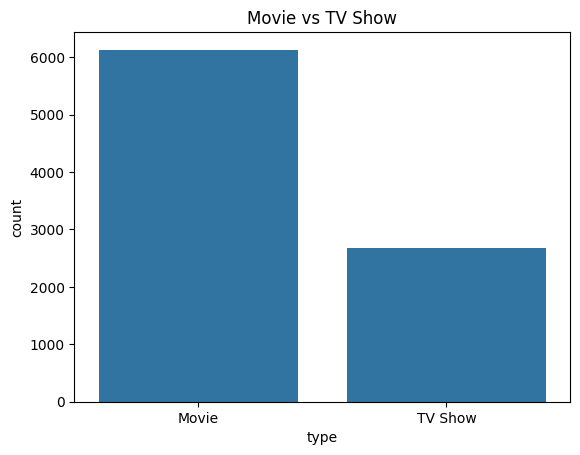

<Figure size 640x480 with 0 Axes>

In [334]:
d["type"].value_counts()
sns.countplot(data=d, x="type")

plt.title("Movie vs TV Show")
plt.show()
plt.savefig("movie_vs_tv_show.png")

**Temuan:** Film mencakup 69,6% katalog, sementara serial TV hanya 30,4%.

**Artinya bagi bisnis:** Netflix masih bertumpu pada film untuk volume katalog.
Namun serial biasanya mendorong retensi karena penonton kembali tiap episode,
jadi kecilnya porsi serial perlu dilihat bersama tren penambahan konten per tahun

**Pertanyaan:** 	Negara mana yang paling banyak menghasilkan konten?

In [335]:
peta = (d["country"]
        .str.split(", ")
        .explode()
        .value_counts()
        .rename_axis("negara")
        .reset_index(name="judul"))

# Menghapus data 'Unknown' agar tidak mengacaukan visualisasi peta
peta = peta[peta["negara"] != "Unknown"]

px.choropleth(peta, locations="negara", locationmode="country names",
              color="judul", title="Jumlah judul per negara").show()
plt.savefig("jumlah_judul_per_negara.png")

<Figure size 640x480 with 0 Axes>

In [336]:
c = d.country.str.split(', ').explode(); c = c[c!='Unknown']
print('Top 10 Country:')
c.value_counts().head(10)

Top 10 Country:


,count
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


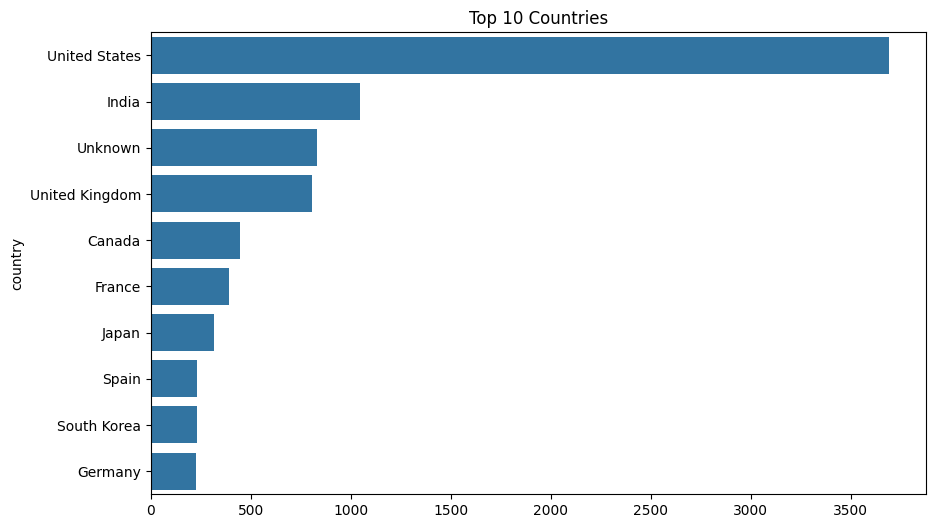

<Figure size 640x480 with 0 Axes>

In [337]:
country_df = d["country"].str.split(", ").explode()
top_country = country_df.value_counts().head(10)
plt.figure(figsize=(10,6))

sns.barplot(
    x=top_country.values,
    y=top_country.index
)

plt.title("Top 10 Countries")

plt.show()
plt.savefig("top_10_countries.png")

In [338]:
x = d.assign(negara=d["country"].str.split(", ")).explode("negara").reset_index(drop=True)
top = ["United States", "India", "United Kingdom"]
(pd.crosstab(x.loc[x["negara"].isin(top), "negara"],
             x.loc[x["negara"].isin(top), "type"],
             normalize="index") * 100).round(1)

type,Movie,TV Show
negara,,
India,92.0,8.0
United Kingdom,66.3,33.7
United States,74.6,25.4


In [339]:
# Persentase film vs serial per negara, diurutkan dari porsi film terbesar
ct = (pd.crosstab(x.loc[x["negara"].isin(top), "negara"],
                  x.loc[x["negara"].isin(top), "type"],
                  normalize="index") * 100).round(1)
ct = ct.sort_values("Movie")   # urutan terbalik, karena bar horizontal digambar dari bawah

fig = go.Figure()
for tipe, warna in [("Movie", "#B20710"), ("TV Show", "#8C8C8C")]:
    fig.add_bar(y=ct.index, x=ct[tipe], name=tipe, orientation="h",
                marker_color=warna,
                text=ct[tipe].astype(str) + "%", textposition="inside",
                textfont=dict(color="white", size=14))

fig.update_layout(
    barmode="stack",
    title="India hampir seluruhnya film (92%), UK paling seimbang (34% TV show)",
    xaxis=dict(title="Porsi katalog (%)", range=[0, 100]),
    yaxis=dict(title=""),
    legend=dict(orientation="h", y=-0.2, title=""),
    template="simple_white",
    height=350,
)
fig.show()
plt.savefig("porsi_katalog_per_negara.png")

<Figure size 640x480 with 0 Axes>

In [340]:
x = d.assign(negara=d["country"].str.split(", "),
                    genre=d["listed_in"].str.split(", "))
x = x.explode("negara", ignore_index=True).explode("genre", ignore_index=True)
x = x[x["negara"].isin(["United States", "India", "United Kingdom"])]
pd.crosstab(x["genre"], x["negara"], normalize="columns").round(3).sort_values("India", ascending=False).head(10)

negara,India,United Kingdom,United States
genre,,,
International Movies,0.308,0.095,0.024
Dramas,0.236,0.110,0.123
Comedies,0.115,0.051,0.100
Independent Movies,0.060,0.042,0.058
Action & Adventure,0.049,0.047,0.060
Romantic Movies,0.043,0.021,0.033
Music & Musicals,0.034,0.020,0.022
Thrillers,0.033,0.034,0.043
International TV Shows,0.024,0.072,0.011


**Temuan:** Konten paling banyak didominasi oleh negara US 3690, india 1046 dan UK 806 konten yang memegang 55,4% persentase judul-negara, dan sepuluh teratas 75,5%.

India hampir seluruhnya movie (92,0%), US 74,6%, UK paling seimbang dengan TV show mencapai 33,7%

**Artinya bagi bisnis:** Kontribusi tiap negara ke katalog tidak seragam.
Konten India menambah volume film, sedangkan UK lebih menopang
katalog serial. Jika Netflix ingin memperkuat serial (yang cenderung
mendorong retensi penonton), UK adalah contoh yang bisa dipelajari,
sedangkan serial India masih punya ruang tumbuh (hipotesis)

**Rekomendasi Business:** Kembangkan produksi lokal di pasar besar yang kontennya masih tipis. Artinya prioritaskan kajian kelayakan produksi lokal di negara berpenduduk besar yang kontennya sedikit, dan uji dulu dengan data pelanggan serta jam tonton sebelum berinvestasi.”

**Batasan:** Butuh data penduduk atau pelanggan per negara

**Pertanyaan:**	Genre apa yang paling banyak?

In [341]:
g = d.listed_in.str.split(', ').explode()

In [342]:
print('Top 10 Genre:')
g.value_counts().head(15)

Top 10 Genre:


,count
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


In [343]:
n = len(d)
ada_drama = d["listed_in"].str.contains("Drama")
ada_comedy = d["listed_in"].str.contains("Comedies")

print(f"Drama : {ada_drama.sum():,} judul = {ada_drama.mean()*100:.1f}% dari {n:,}")
print(f"Comedy: {ada_comedy.sum():,} judul = {ada_comedy.mean()*100:.1f}% dari {n:,}")

Drama : 3,190 judul = 36.2% dari 8,807
Comedy: 2,255 judul = 25.6% dari 8,807


**Temuan:** Genre terbanyak Drama yaitu 36,2%, dan Comedy 25,6%

Analisis saya mengeluarkan Label International Movies dari top 1 sebab label ini hampir selalu menempel pada genre lain: hanya 3 dari 2.752 film yang bertanda International Movies saja. Pasangan terbanyaknya Dramas (1.483), Comedies (804), Action & Adventure (398), Romantic Movies (372), dan Documentaries (296).

**Business recommendation:** Dukung genre yang naik, tetapi jaga segmen niche agar tidak hilang

**Pertanyaan:** Berapa jumlah konten yang ditambahkan setiap tahun?

In [344]:
pd.crosstab(d.year_added, d.type).loc[2015:2021]

type,Movie,TV Show
year_added,,
2015.0,56,26
2016.0,253,176
2017.0,839,349
2018.0,1237,412
2019.0,1424,592
2020.0,1284,595
2021.0,993,505


In [345]:
print('jeda rilis-masuk netflix=',((d.year_added-d.release_year)<=1).mean().round(3))

jeda rilis-masuk netflix= 0.55


In [346]:
# Membuat DataFrame tren dari cross-tabulation
tren = pd.crosstab(d["year_added"], d["type"]).loc[2015:2021].reset_index()
tren["year_added"] = tren["year_added"].astype(int)

# Melakukan melt agar format data sesuai untuk Plotly Express
tren_melted = tren.melt(id_vars="year_added", value_vars=["Movie", "TV Show"],
                        var_name="Tipe Konten", value_name="Jumlah Judul")

# Membuat line chart interaktif menggunakan Plotly Express
fig = px.line(
    tren_melted,
    x="year_added",
    y="Jumlah Judul",
    color="Tipe Konten",
    markers=True,
    color_discrete_map={"Movie": "#B20710", "TV Show": "#8C8C8C"},
    title="Tren Penambahan Konten Netflix per Tahun (2015-2021)"
)

fig.update_layout(
    xaxis=dict(dtick=1, title="Tahun Ditambahkan"),
    yaxis=dict(title="Jumlah Judul"),
    template="simple_white"
)
fig.show()
plt.savefig("tren_penambahan_konten.png")

<Figure size 640x480 with 0 Axes>

**Temuan:** Jumlah judul film yang ditambahkan naik tajam sampai 2019 sebanyak 1424 judul, lalu melambat di 2020. Sedangkan pertumbuhan TV show lebih lambat dibanding film dengan grafik terus naik sampai 2020 dengan 595 judul. 55% ditambahkan paling lambat setahun setelah rilis.

**Batasan:** Data 2021 belum lengkap dikarenakan berhenti di bulan september, jadi penurunan di tahun 2021 tidak bisa langsung disimpulkan sebagai tren.

**Pertanyaan:** Sutradara dengan konten terbanyak?

In [347]:
dr = d.director.str.split(', ').explode()
print('Top 10 Director:')
dr.value_counts().head(10)

Top 10 Director:


,count
director,
Unknown,2634
Rajiv Chilaka,22
Jan Suter,21
Raúl Campos,19
Suhas Kadav,16
Marcus Raboy,16
Jay Karas,15
Cathy Garcia-Molina,13
Martin Scorsese,12


In [348]:
d[d["director"] == "Unknown"]["type"].value_counts()

,count
type,
TV Show,2446
Movie,188


**Temuan:** Terdapat 2.634 baris tanpa sutradara, sekitar 30% dengan masing-masing 2.446 serial dan 188 film. Artinya 91% serial tidak punya data sutradara.

**Batasan:** Jangan membuat peringkat kreator dari data ini

**Pertanyaan:** Seperti apa sebaran TV-MA, TV-14, R, dan seterusnya? Apakah Netflix condong ke konten dewasa?

In [349]:
print('\nRATING per type (%):')
(pd.crosstab(d.rating, d.type, normalize='columns')*100).round(1).sort_values('Movie',ascending=False).head(5)


RATING per type (%):


type,Movie,TV Show
rating,,
TV-MA,33.6,42.8
TV-14,23.3,27.4
R,13.0,0.1
TV-PG,8.8,12.1
PG-13,8.0,0.0


In [350]:
d["rating"].value_counts()

,count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


**Temuan:** TV-MA 3.207 judul (36,4%) dan TV-14 2.160 (24,5%) mendominasi, jadi katalog ini condong ke penonton remaja dan dewasa

**Pertanyaan:** siapa aktor yang paling sering muncul dan paling sering bersama?

In [351]:
dr = d.cast.str.split(', ').explode()
print('Top 10 Cast:')
dr.value_counts().head(10)

Top 10 Cast:


,count
cast,
Unknown,825
Anupam Kher,43
Shah Rukh Khan,35
Julie Tejwani,33
Naseeruddin Shah,32
Takahiro Sakurai,32
Rupa Bhimani,31
Om Puri,30
Akshay Kumar,30


In [352]:
#Aktor yang sering bermain bersama: hitung semua pasangan dalam satu daftar pemeran.
from itertools import combinations
from collections import Counter

pasangan = Counter()
for daftar in d.loc[d["cast"] != "Unknown", "cast"].str.split(", "):
    pasangan.update(combinations(sorted(set(daftar)), 2))
pasangan.most_common(8)

[(('Julie Tejwani', 'Rupa Bhimani'), 31),
 (('Julie Tejwani', 'Rajesh Kava'), 24),
 (('Rajesh Kava', 'Rupa Bhimani'), 22),
 (('Jigna Bhardwaj', 'Julie Tejwani'), 21),
 (('Jigna Bhardwaj', 'Rajesh Kava'), 20),
 (('Jigna Bhardwaj', 'Rupa Bhimani'), 20),
 (('Jigna Bhardwaj', 'Vatsal Dubey'), 18),
 (('Julie Tejwani', 'Vatsal Dubey'), 18)]

**Temuan:** Banyak judul yang tidak memiliki daftar aktor sehingga belum dapat disimpulkan.

pada aktor yang sering muncul bersama ternyata mencerminkan satu kelompok serial animasi anak India: judul yang saya periksa adalah Chhota Bheem dan sejenisnya, dan 25 dari 31 judulnya berlabel Children & Family Movies. Jadi ini bukan “kemitraan aktor” dalam arti umum.

**Pertanyaan:** •	Apakah Netflix lebih banyak menampilkan konten baru atau lama?

In [353]:
selisih = d["year_added"] - d["release_year"]
(selisih <= 1).mean().round(3)

np.float64(0.55)

In [354]:
(selisih <= 1)[d["type"] == "Movie"].mean()

np.float64(0.4961670200619801)

In [355]:
(selisih <= 1)[d["type"] == "TV Show"].mean()                                    # pangsa konten baru, dirilis paling lama 1 tahun sebelum ditambahkan

np.float64(0.671898355754858)

In [356]:
(selisih <= 1).groupby(d["year_added"]).mean()     # per tahun

,0
year_added,
2008.0,0.500000
2009.0,0.500000
2010.0,0.000000
2011.0,0.076923
2012.0,0.666667
2013.0,0.818182
2014.0,0.833333
2015.0,0.817073
2016.0,0.655012


In [357]:
selisih = d["year_added"] - d["release_year"]
baru = ((selisih <= 1).groupby(d["year_added"]).mean() * 100).loc[2015:2021]
baru.index = baru.index.astype(int)
baru_dict = baru.to_dict()

tahun_list = sorted(list(baru_dict.keys()))

fig4 = go.Figure()

# Menggambar garis tren menggunakan visualisasi Plotly standar
fig4.add_trace(go.Scatter(
    x=tahun_list,
    y=[baru_dict[t] for t in tahun_list],
    mode="lines+markers",
    name="Konten baru (<= 1 tahun)",
    line=dict(color="#B20710", width=3),
    marker=dict(size=8)
))

# Menambahkan anotasi label nilai untuk tahun 2015 dan 2021
for t in (2015, 2021):
    if t in baru_dict:
        fig4.add_annotation(
            x=t,
            y=baru_dict[t],
            text=f"{baru_dict[t]:.0f}%",
            showarrow=False,
            yshift=15,
            font=dict(color="#B20710", size=13, family="Arial")
        )

# Mengatur tata letak visualisasi (layout)
fig4.update_layout(
    title=dict(
        text=f"Pangsa konten baru menyusut dari {baru_dict[2015]:.0f}% (2015) ke {baru_dict[2021]:.0f}% (2021)",
        font=dict(size=14)
    ),
    xaxis=dict(dtick=1, title="Tahun judul ditambahkan"),
    yaxis=dict(title="% judul dirilis paling lama 1 tahun sebelum ditambahkan", range=[0, 100]),
    template="simple_white"
)

fig4.show()
plt.savefig("pangsa_konten_baru.png")

<Figure size 640x480 with 0 Axes>

**Temuan** 55% tergolong baru, tetapi pangsanya menyusut: 65% (2016), 55% (2020). Film 49,6% vs serial 67%

**Business recommendation:** Tinjau film keluaran lama; perkuat film baru atau kurasi katalog lama lewat rekomendasi

## 3. Diagnostics Analytics

**Pertanyaan:** Kenapa Drama mendominasi?

In [358]:
ada_drama = d["listed_in"].str.contains("Drama")
print(ada_drama.groupby(d["type"]).mean())
print(ada_drama.groupby(d["year_added"]).mean())

type
Movie      0.395857
TV Show    0.285127
Name: listed_in, dtype: float64
year_added
2008.0    0.500000
2009.0    0.500000
2010.0    0.000000
2011.0    1.000000
2012.0    0.000000
2013.0    0.363636
2014.0    0.125000
2015.0    0.243902
2016.0    0.251748
2017.0    0.356061
2018.0    0.388114
2019.0    0.361111
2020.0    0.372006
2021.0    0.366489
Name: listed_in, dtype: float64


Jadi drama dominan karena labelnya luas, "Drama" sering dipasangkan dengan genre lain, contohnya Dramas + International Movies 1.483 judul. Juga genre tersebut sangat kuat di beberapa negara, dan naik sejak 2017. Alasan yang lebih dalam (biaya produksi, selera penonton) tidak bisa dijawab tanpa data penayangan atau biaya.

**Pertanyaan:** kenapa US paling mendominasi?

In [359]:
usa = d["country"].str.split(", ").apply(lambda x: "United States" in x)
ada = d["country"] != "Unknown"
usa[ada].groupby(d.loc[ada, "year_added"]).mean()

,country
year_added,
2008.0,1.000000
2009.0,0.500000
2010.0,1.000000
2011.0,0.923077
2012.0,1.000000
2013.0,0.909091
2014.0,0.916667
2015.0,0.721519
2016.0,0.495122


In [360]:
ada = d["country"] != "Unknown"
melibatkan_as = d["country"].str.split(", ").apply(lambda l: "United States" in l)
as_th = (melibatkan_as[ada].groupby(d.loc[ada, "year_added"]).mean() * 100).loc[2015:2021]
as_th.index = as_th.index.astype(int)
as_th_dict = as_th.to_dict()

tahun_list = sorted(list(as_th_dict.keys()))

fig3 = go.Figure()

# Menggambar garis pangsa pasar AS menggunakan Plotly standar
fig3.add_trace(go.Scatter(
    x=tahun_list,
    y=[as_th_dict[t] for t in tahun_list],
    mode="lines+markers",
    name="Pangsa AS",
    line=dict(color="#B20710", width=3),
    marker=dict(size=8)
))

# Menambahkan anotasi nilai untuk tahun 2015, 2018, dan 2021
for t in (2015, 2018, 2021):
    if t in as_th_dict:
        fig3.add_annotation(
            x=t,
            y=as_th_dict[t],
            text=f"{as_th_dict[t]:.0f}%",
            showarrow=False,
            yshift=15,
            font=dict(color="#B20710", size=13, family="Arial")
        )

# Mengatur tata letak visualisasi (layout)
fig3.update_layout(
    title=dict(
        text=f"Pangsa AS jatuh dari {as_th_dict[2015]:.0f}% (2015) ke {as_th_dict[2018]:.0f}% (2018), lalu pulih ke {as_th_dict[2021]:.0f}% (2021)",
        font=dict(size=14)
    ),
    xaxis=dict(dtick=1, title="Tahun judul ditambahkan"),
    yaxis=dict(title="% judul yang melibatkan AS (negara diketahui)", range=[0, 100]),
    template="simple_white",
    margin=dict(b=100)
)

# Menambahkan catatan kaki mengenai data tahun 2015
fig3.add_annotation(
    x=0,
    y=-0.25,
    xref="paper",
    yref="paper",
    showarrow=False,
    xanchor="left",
    text="Catatan: 2015 hanya 79 judul bernegara diketahui, hati-hati membaca angka tahun ini.",
    font=dict(size=11, color="#666")
)

fig3.show()

AS terlibat di 3.690 judul (41,9%; 46,3% jika hanya menghitung yang negaranya diketahui). Dari jumlah itu, 2.819 produksi murni AS dan 871 koproduksi. Pangsa AS juga lebih tinggi pada film (44,9%) daripada serial (35,1%). Per tahun: 49,5% (2016), 41,1%, 39,2%, 46,1%, 46,8%, 55,0% (2021). Tidak ada tren pergeseran menjauhi AS dari tahun 2016.
**catatan:** Hipotesis yang masuk akal (Netflix perusahaan AS, besarnya industri hiburan AS, lisensi katalog Hollywood) tidak bisa diuji dengan data ini. Dibutuhkan data eksternal seperti jumlah produksi film per negara atau jumlah pelanggan.

## 4. Analisis Tren

Bandingkan pangsa genre antar periode

In [361]:
b = d.dropna(subset=["year_added"]).copy()
b["periode"] = np.where(b["year_added"] <= 2018, "2014-2018", "2019-2021")
x = b.assign(genre=b["listed_in"].str.split(", ")).explode("genre", ignore_index=True)
pangsa = x.groupby(["genre", "periode"]).size().unstack(fill_value=0) / b["periode"].value_counts()
pangsa["selisih_poin"] = (pangsa["2019-2021"] - pangsa["2014-2018"]) * 100
cukup = x["genre"].value_counts() >= 150
pangsa[cukup.reindex(pangsa.index)].sort_values("selisih_poin", ascending=False).head(5)

periode,2014-2018,2019-2021,selisih_poin
genre,,,
Comedies,0.158343,0.210458,5.211488
Romantic Movies,0.052585,0.081031,2.844577
Children & Family Movies,0.059342,0.081402,2.205987
Action & Adventure,0.085488,0.105322,1.983405
Reality TV,0.017920,0.035973,1.805246


In [362]:
b = d.dropna(subset=["year_added"]).copy()
b["periode"] = np.where(b["year_added"] <= 2018, "s.d. 2018", "2019-2021")

x = b.assign(genre=b["listed_in"].str.split(", ")).explode("genre", ignore_index=True)

jumlah = x.groupby(["genre", "periode"]).size().unstack(fill_value=0)
pangsa = jumlah / b["periode"].value_counts() * 100     # % dari total judul per periode

pilihan = ["Comedies", "Documentaries", "Docuseries", "Stand-Up Comedy"]

tabel = pd.DataFrame({
    "Judul s.d. 2018":   jumlah.loc[pilihan, "s.d. 2018"],
    "Judul 2019-2021":   jumlah.loc[pilihan, "2019-2021"],
    "Pangsa s.d. 2018 (%)": pangsa.loc[pilihan, "s.d. 2018"].round(1),
    "Pangsa 2019-2021 (%)": pangsa.loc[pilihan, "2019-2021"].round(1),
})
tabel["Selisih (poin)"] = (tabel["Pangsa 2019-2021 (%)"] - tabel["Pangsa s.d. 2018 (%)"]).round(1)

print("Jumlah judul per periode:", b["periode"].value_counts().to_dict())
tabel

Jumlah judul per periode: {'2019-2021': 5393, 's.d. 2018': 3404}


,Judul s.d. 2018,Judul 2019-2021,Pangsa s.d. 2018 (%),Pangsa 2019-2021 (%),Selisih (poin)
genre,,,,,
Comedies,539,1135,15.8,21.0,5.2
Documentaries,464,405,13.6,7.5,-6.1
Docuseries,154,240,4.5,4.5,0.0
Stand-Up Comedy,212,131,6.2,2.4,-3.8


In [363]:
b = d.dropna(subset=["year_added"]).copy()
b["periode"] = np.where(b["year_added"] <= 2018, "awal", "akhir")      # s.d. 2018 vs 2019-2021
x = b.assign(genre=b["listed_in"].str.split(", ")).explode("genre", ignore_index=True)

jumlah = x.groupby(["genre", "periode"]).size().unstack(fill_value=0)
pangsa = jumlah / b["periode"].value_counts() * 100
pangsa["selisih"] = pangsa["akhir"] - pangsa["awal"]
pangsa = pangsa[x["genre"].value_counts().reindex(pangsa.index) >= 150]   # buang genre terlalu kecil
g = pd.concat([pangsa.nlargest(4, "selisih"), pangsa.nsmallest(4, "selisih")]).sort_values("selisih")
naik, turun = pangsa["selisih"].idxmax(), pangsa["selisih"].idxmin()

# Mengganti variabel warna kustom dengan kode HEX standar
warna_merah = "#B20710"
warna_abu = "#8C8C8C"
warna = [warna_merah if n in (naik, turun) else warna_abu for n in g.index]

fig2 = go.Figure(go.Bar(
    x=g["selisih"].round(1),
    y=g.index,
    orientation="h",
    marker_color=warna,
    text=[f"{v:+.1f}" for v in g["selisih"]],
    textposition="outside"
))

fig2.add_vline(x=0, line_color="#595959", line_width=1)

fig2.update_layout(
    title=f"{naik} naik paling tajam ({pangsa.loc[naik, 'selisih']:+.1f} poin), "
          f"{turun} turun paling dalam ({pangsa.loc[turun, 'selisih']:+.1f} poin)",
    height=450,
    template="simple_white"
)

fig2.update_xaxes(
    title="Perubahan pangsa genre (poin persentase), s.d. 2018 -> 2019-2021",
    range=[g["selisih"].min() - 1.5, g["selisih"].max() + 1.5]
)
fig2.show()
plt.savefig("perubahan_pangsa_genre.png")

<Figure size 640x480 with 0 Axes>

**Temuan:** Pada tahun 2019-2021, komedi adalah kenaikan pangsa terbesar (+5,2 poin).

**Rekomendasi bisnis:** Genre yang naik berarti peluang, tetapi komedi sudah ramai (jumlahnya dua kali lipat), jadi butuh pembeda. Dokumenter pada serial lebih stabil daripada dokumenter film. Lalu uji apakah volume komedi sebanding dengan jam tonton dan tentukan secara apakah dokumenter dan stand-up dipertahankan sebagai konten niche atau dikurangi

**Pertanyaan:** Bagaimana pertumbuhan judul terhadap negara yang di tambahkan ke katalog?

In [364]:
b = d.dropna(subset=["year_added"]).copy()
b["periode"] = np.where(b["year_added"] <= 2018, "<=2018", "2019-2021")
b['gap'] = b.year_added - b.release_year
x = b.assign(negara=b["country"].str.split(", ")).explode("negara", ignore_index=True)
x = x[x["negara"] != "Unknown"]

# Memperbaiki filter sB dan menghilangkan indentasi yang tidak diinginkan
sB = x[x["periode"] == "2019-2021"]

cnt = x.groupby(["negara", "periode"]).size().unstack(fill_value=0)
cnt["median"] = sB.groupby("negara")["release_year"].median()
cnt["Tergolong baru <2 tahun"] = sB.groupby("negara")["gap"].apply(lambda g: round((g <= 2).mean() * 100))
cnt["pangsa_total"] = (cnt["<=2018"] + cnt["2019-2021"]) / len(b) * 100
cnt["pengali"] = cnt["2019-2021"] / cnt["<=2018"].replace(0, np.nan)

cnt[(cnt["pangsa_total"] < 2) & (cnt["2019-2021"] >= 40)].sort_values("pengali", ascending=False)

periode,2019-2021,<=2018,median,Tergolong baru <2 tahun,pangsa_total,pengali
negara,,,,,,
Egypt,113,4,2012.0,35.0,1.329999,28.250000
Nigeria,99,4,2018.0,59.0,1.170854,24.750000
Philippines,76,7,2016.0,45.0,0.943503,10.857143
South Africa,42,20,2017.0,50.0,0.704786,2.100000
Indonesia,59,31,2019.0,75.0,1.023076,1.903226
Turkey,73,40,2017.0,41.0,1.284529,1.825000
Italy,64,36,2019.0,70.0,1.136751,1.777778
Brazil,60,37,2019.5,83.0,1.102649,1.621622
Belgium,50,40,2018.0,74.0,1.023076,1.250000


**Temuan:**

* Nigeria menunjukkan pertumbuhan jumlah konten yang sangat tinggi, tetapi porsinya di katalog masih kecil. Negara seperti ini layak menjadi prioritas untuk studi kelayakan investasi konten lokal karena berpotensi menjadi pasar pertumbuhan berikutnya. Pertumbuhannya tinggi, porsinya kecil, 86% judulnya dirilis 2015 atau sesudahnya, dan penambahannya tersebar dalam tiga tahun (29, 42, 28 judul pada 2019, 2020, 2021).
* Mesir : Median tahun rilisnya 2012, ada 16 judul rilis sebelum 2000, dan 106 dari 113 judul ditambahkan hanya pada 2019–2020 (54 dan 52). Pola itu lebih mirip pembelian satu paket pustaka film lama daripada tumbuhnya produksi lokal. Data tidak mendukung klaim “tambah investasi produksi” untuk Mesir.
* Filipina menumpuk di 2019–2020 (39 dan 32 dari 76 judul), hampir semuanya film (97%), jadi kemungkinan serupa dengan Mesir tetapi tidak sekuat itu.
* Brasil, Indonesia, dan Italia berisi konten yang sangat baru (70–83% dirilis dalam 2 tahun sebelum ditambahkan), tetapi pertumbuhannya lebih moderat (1,6–1,9×).

